In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

SPLITS_DIR = Path("splits_v2")   # the current split (after the label review)
CACHE_DIR  = Path("cache_256")   # resized images + cached_manifest.csv

Load the cached image table and check it

In [3]:
df = pd.read_csv(CACHE_DIR / "cached_manifest.csv",
                 dtype={"leaf_id": str}, keep_default_na=False)

print("Rows (images):", len(df))
print("All cached OK:", df["cache_ok"].all())

counts = df.groupby(["split", "dataset"]).size().unstack(fill_value=0)
counts["total"] = counts.sum(axis=1)
counts

Rows (images): 29936
All cached OK: True


dataset,PlantDoc,PlantVillage,PlantWild,total
split,,,,
test_lab,0,3950,0,3950
test_wild,0,0,1909,1909
train,0,18475,0,18475
val_lab,0,3972,0,3972
val_wild,1630,0,0,1630


Images per class

In [4]:
classes = pd.read_json(SPLITS_DIR / "classes.json")
order = classes.sort_values("index")["id"].tolist()

SPLITS = ["train", "val_lab", "test_lab", "val_wild", "test_wild"]
per_class = (df.groupby(["class_id", "split"]).size()
               .unstack(fill_value=0)
               .reindex(index=order, columns=SPLITS))
per_class

split,train,val_lab,test_lab,val_wild,test_wild
class_id,,,,,
apple_scab,440,95,95,89,83
apple_cedar_rust,192,43,40,84,114
apple_healthy,1151,247,247,49,134
pepper_bacterial_spot,699,151,147,63,45
pepper_healthy,1034,222,222,44,114
corn_gray_leaf_spot,359,77,77,62,80
corn_northern_leaf_blight,689,148,148,171,98
corn_common_rust,834,179,179,115,148
grape_black_rot,828,176,176,59,19


How unbalanced is each split

In [5]:
summary = pd.DataFrame({
    "images":         per_class.sum(),
    "smallest class": per_class.min(),
    "largest class":  per_class.max(),
})
summary["imbalance ratio"] = (summary["largest class"] / summary["smallest class"]).round(1)
summary["smallest is"] = per_class.idxmin()
summary["largest is"]  = per_class.idxmax()
summary

,images,smallest class,largest class,imbalance ratio,smallest is,largest is
split,,,,,,
train,18475,192,3750,19.5,apple_cedar_rust,tomato_yellow_leaf_curl
val_lab,3972,43,804,18.7,apple_cedar_rust,tomato_yellow_leaf_curl
test_lab,3950,40,803,20.1,apple_cedar_rust,tomato_yellow_leaf_curl
val_wild,1630,44,171,3.9,pepper_healthy,corn_northern_leaf_blight
test_wild,1909,19,148,7.8,grape_black_rot,corn_common_rust


Share for each class from the total of each split

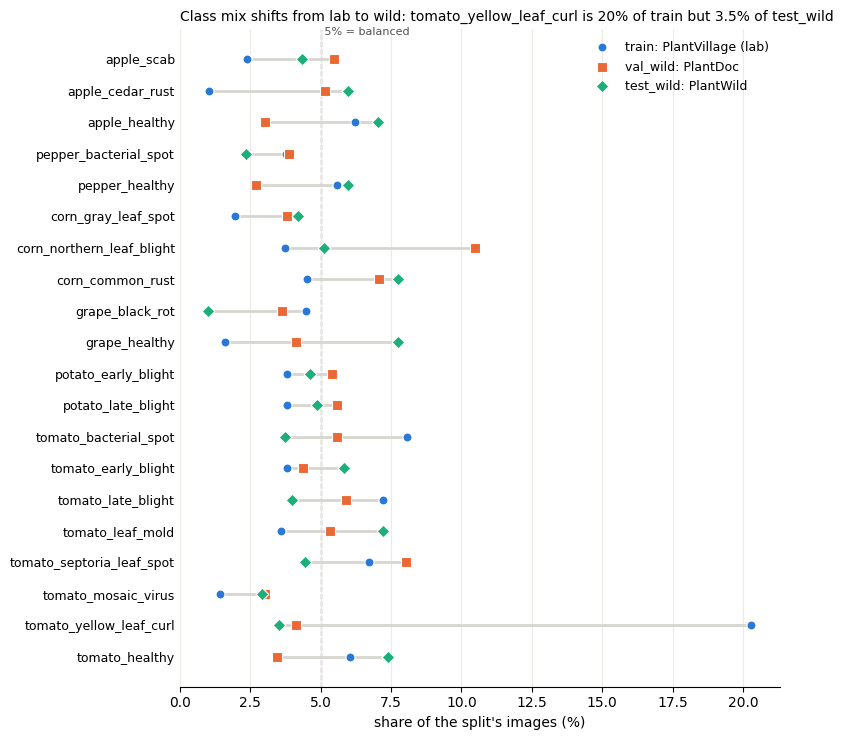

In [6]:
SHOW = ["train", "val_wild", "test_wild"]
share = per_class[SHOW] / per_class[SHOW].sum() * 100

STYLE = {"train":     ("#2a78d6", "o", "train: PlantVillage (lab)"),
         "val_wild":  ("#eb6834", "s", "val_wild: PlantDoc"),
         "test_wild": ("#1baf7a", "D", "test_wild: PlantWild")}

fig, ax = plt.subplots(figsize=(8, 7.5))
y = np.arange(len(share))[::-1]
ax.hlines(y, share.min(axis=1), share.max(axis=1), color="#d6d5cf", lw=2, zorder=1)
for split, (colour, marker, label) in STYLE.items():
    ax.scatter(share[split], y, s=42, color=colour, marker=marker, label=label,
               edgecolor="white", linewidth=0.8, zorder=3)
ax.axvline(100 / len(share), color="#8a8984", lw=1, ls="--", zorder=0)
ax.text(100 / len(share), len(share) - 0.3, " 5% = balanced", color="#52514e", fontsize=8, va="bottom")

gap = (share["train"] - share["test_wild"]).abs()
c = gap.idxmax()
ax.set_title(f"Class mix shifts from lab to wild: {c} is {share.at[c, 'train']:.0f}% of train "
             f"but {share.at[c, 'test_wild']:.1f}% of test_wild", fontsize=10, loc="left")
ax.set_yticks(y, share.index, fontsize=9)
ax.set_xlabel("share of the split's images (%)")
ax.set_xlim(0, share.values.max() * 1.05)
ax.grid(axis="x", color="#ebeae5", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="upper right", frameon=False, fontsize=9)
fig.tight_layout()

Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/q1_class_share.png", dpi=200)
plt.show()

Image sizes (the resolution gap)

In [8]:
df["source"] = np.select(
    [df["dataset"] == "PlantVillage",
     df["dataset"] == "PlantDoc",
     df["source_split"] == "v1"],
    ["PlantVillage (lab)", "PlantDoc (val_wild)", "PlantWild v1 (test_wild, healthy)"],
    default="PlantWild v2 (test_wild, disease)")

df["short_side"] = df[["width", "height"]].min(axis=1)
df["aspect"] = df[["width", "height"]].max(axis=1) / df["short_side"]

sizes = df.groupby("source").agg(
    images            = ("short_side", "size"),
    median_width      = ("width", "median"),
    median_height     = ("height", "median"),
    median_short_side = ("short_side", "median"),
    pct_below_224     = ("short_side", lambda s: round(100 * (s < 224).mean(), 1)),
    pct_not_square    = ("aspect", lambda a: round(100 * (a > 1.05).mean(), 1)),
)
sizes

,images,median_width,median_height,median_short_side,pct_below_224,pct_not_square
source,,,,,,
PlantDoc (val_wild),1630,700.0,597.5,540.0,6.1,93.2
PlantVillage (lab),26397,256.0,256.0,256.0,0.0,0.0
"PlantWild v1 (test_wild, healthy)",537,723.0,691.0,612.0,2.0,86.4
"PlantWild v2 (test_wild, disease)",1372,640.0,500.0,480.0,8.7,95.0


The background gap

In [11]:
bg = df.groupby("source").agg(
    plant_border_pct = ("border_green", lambda s: round(100 * s.median(), 1)),
    border_std       = ("border_std", "median"),
    brightness       = ("brightness", "median"),
    saturation       = ("saturation", "median"),
).round(1)
bg

,plant_border_pct,border_std,brightness,saturation
source,,,,
PlantDoc (val_wild),45.0,45.9,118.9,105.7
PlantVillage (lab),1.1,28.7,116.4,65.2
"PlantWild v1 (test_wild, healthy)",16.7,40.6,146.5,86.2
"PlantWild v2 (test_wild, disease)",50.3,46.2,119.6,109.1


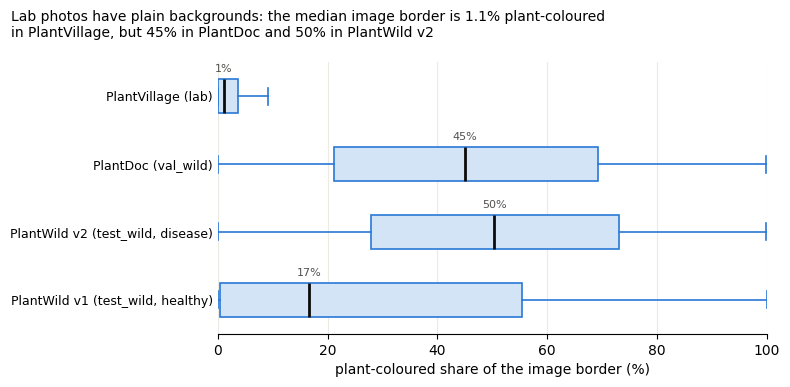

In [12]:
ORDER = ["PlantVillage (lab)", "PlantDoc (val_wild)",
         "PlantWild v2 (test_wild, disease)", "PlantWild v1 (test_wild, healthy)"]
data = [100 * df.loc[df["source"] == s, "border_green"] for s in ORDER]
med = {s: d.median() for s, d in zip(ORDER, data)}

fig, ax = plt.subplots(figsize=(8, 3.9))
ax.boxplot(data, vert=False, widths=0.5, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#d4e4f7", edgecolor="#2a78d6", linewidth=1.2),
           whiskerprops=dict(color="#2a78d6", linewidth=1.2),
           capprops=dict(color="#2a78d6", linewidth=1.2),
           medianprops=dict(color="#0b0b0b", linewidth=2))
ax.set_yticks(range(1, len(ORDER) + 1), ORDER, fontsize=9)
ax.invert_yaxis()
for i, s in enumerate(ORDER, 1):
    ax.text(med[s], i - 0.33, f"{med[s]:.1f}%" if med[s] < 1 else f"{med[s]:.0f}%",
            ha="center", va="bottom", fontsize=8, color="#52514e")
ax.set_xlim(0, 100)
ax.set_xlabel("plant-coloured share of the image border (%)")
fig.suptitle(f"Lab photos have plain backgrounds: the median image border is {med[ORDER[0]]:.1f}% plant-coloured\n"
             f"in PlantVillage, but {med[ORDER[1]]:.0f}% in PlantDoc and {med[ORDER[2]]:.0f}% in PlantWild v2",
             fontsize=10, x=0.02, ha="left")
ax.grid(axis="x", color="#ebeae5", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig("figures/q1_background_gap.png", dpi=200)
plt.show()

Checking images backgrounds of datasets

In [15]:
from PIL import Image

def show_samples(sources, n=6, seed=42):
    """n random cached images per source (same seed every run), one row per source."""
    fig, axes = plt.subplots(len(sources), n, figsize=(n * 1.6, len(sources) * 1.8), squeeze=False)
    for r, s in enumerate(sources):
        pick = df[df["source"] == s].sample(n, random_state=seed)
        for c, row in enumerate(pick.itertuples()):
            ax = axes[r, c]
            with Image.open(CACHE_DIR / row.cache_path) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            ax.set_title(row.class_id.replace("_", " "), fontsize=6)
        axes[r, 0].set_ylabel(s.replace(" (", "\n("), fontsize=7, rotation=0, ha="right", va="center")
    fig.tight_layout()
    return fig

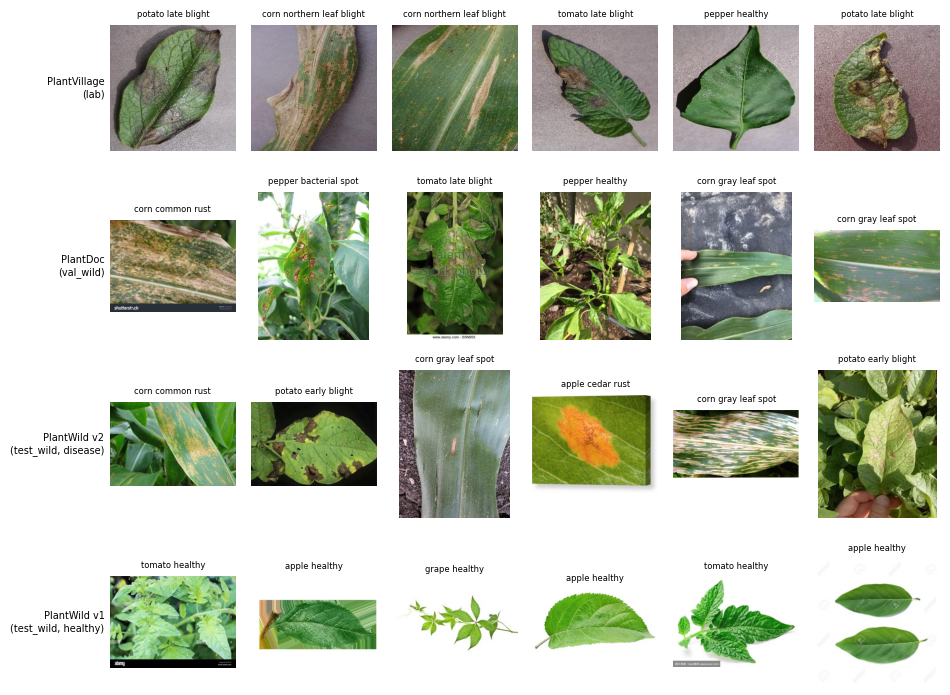

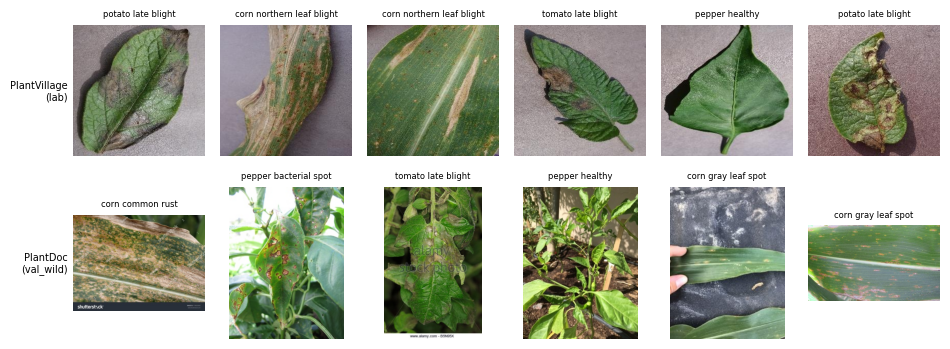

In [16]:
fig = show_samples(ORDER)          # all four sources: for your own inspection only
plt.show()

fig = show_samples(ORDER[:2])      # report version: PlantVillage and PlantDoc only
fig.savefig("figures/q1_samples_lab_vs_wild.png", dpi=200)
plt.show()

How many images have a plain, plant-free border?

In [17]:
plain = df.groupby("source")["border_green"].agg(
    lambda s: round(100 * (s < 0.05).mean(), 1)).rename("pct_plain_border")
plain

source
PlantDoc (val_wild)                  10.8
PlantVillage (lab)                   80.0
PlantWild v1 (test_wild, healthy)    40.6
PlantWild v2 (test_wild, disease)     6.9
Name: pct_plain_border, dtype: float64

The trivial benchmarks

In [18]:
from sklearn.metrics import f1_score, accuracy_score

DISEASE = [c for c in order if not c.endswith("_healthy")]

train = df[df["split"] == "train"]
majority = train.groupby("crop")["class_id"].agg(lambda s: s.value_counts().sort_index().idxmax())
majority

crop
apple                    apple_healthy
bell_pepper             pepper_healthy
corn                  corn_common_rust
grape                  grape_black_rot
potato             potato_early_blight
tomato         tomato_yellow_leaf_curl
Name: class_id, dtype: object

In [19]:
def scores(y_true, y_pred):
    return {
        "accuracy":            accuracy_score(y_true, y_pred),
        "macro_f1_20":         f1_score(y_true, y_pred, labels=order,   average="macro", zero_division=0),
        "macro_f1_16_disease": f1_score(y_true, y_pred, labels=DISEASE, average="macro", zero_division=0),
    }

bench = {}
for split in ["val_lab", "val_wild"]:
    part = df[df["split"] == split]
    pred = part["crop"].map(majority)
    bench[("majority", split)] = scores(part["class_id"], pred)

pd.DataFrame(bench).T.round(3)

accuracy  macro_f1_20  macro_f1_16_disease
majority val_lab      0.448        0.209                0.166
         val_wild     0.259        0.146                0.124

The random-guess benchmark

In [20]:
crop_classes = {c: sorted(df.loc[df["crop"] == c, "class_id"].unique()) for c in df["crop"].unique()}

rng = np.random.default_rng(42)
runs = []
for split in ["val_lab", "val_wild"]:
    part = df[df["split"] == split]
    for _ in range(100):
        pred = [rng.choice(crop_classes[c]) for c in part["crop"]]
        runs.append({"split": split, **scores(part["class_id"], pred)})

runs = pd.DataFrame(runs)
runs.groupby("split").agg(["mean", "std"]).round(3)

accuracy        macro_f1_20        macro_f1_16_disease       
             mean    std        mean    std                mean    std
split                                                                 
val_lab     0.253  0.007       0.284  0.008               0.265  0.008
val_wild    0.293  0.009       0.295  0.010               0.285  0.010

In [21]:
maj = pd.DataFrame(bench).T
maj.index = pd.MultiIndex.from_tuples([("always majority", s) for _, s in maj.index])

rand = runs.groupby("split").mean()
rand.index = pd.MultiIndex.from_product([["random within crop"], rand.index])

benchmarks = pd.concat([maj, rand]).round(3)
benchmarks.index.names = ["benchmark", "split"]

Path("results").mkdir(exist_ok=True)
benchmarks.to_csv("results/benchmarks.csv")
benchmarks

accuracy  macro_f1_20  macro_f1_16_disease
benchmark          split                                               
always majority    val_lab      0.448        0.209                0.166
                   val_wild     0.259        0.146                0.124
random within crop val_lab      0.253        0.284                0.265
                   val_wild     0.293        0.295                0.285